# 03 â€” Shoreline Extraction

This notebook extracts and cleans a test shoreline from the 2024 water mask produced by Notebook 02. It sets up the project paths and required inputs; shoreline extraction itself happens in later cells.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import rioxarray as rxr
import matplotlib.pyplot as plt
import shapely.geometry
import rasterio.features

project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

PROJECT_ROOT = project_root
CONFIG_DIR = PROJECT_ROOT / "config"
DATA_DIR = PROJECT_ROOT / "data"
INTERIM_DIR = DATA_DIR / "interim"
PROCESSED_DIR = DATA_DIR / "processed"
TEST_DIR = INTERIM_DIR / "mombasa_test"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"

for folder in (
    PROCESSED_DIR / "mombasa_test" / "2024",
    FIGURES_DIR,
):
    folder.mkdir(parents=True, exist_ok=True)

STUDY_AREA_PATH = CONFIG_DIR / "study_area.geojson"
WATER_MASK_PATH = TEST_DIR / "water_mask" / "water_mask_2024.tif"
MNDWI_PATH = TEST_DIR / "water_index" / "mndwi_2024.tif"
VALID_MASK_PATH = TEST_DIR / "masked" / "valid_mask_2024.tif"
SHORELINE_OUTPUT_PATH = (
    PROCESSED_DIR / "mombasa_test" / "2024" / "shoreline_2024_test.gpkg"
)

print("PROJECT_ROOT:           ", PROJECT_ROOT)
print("CONFIG_DIR:             ", CONFIG_DIR)
print("DATA_DIR:               ", DATA_DIR)
print("INTERIM_DIR:            ", INTERIM_DIR)
print("PROCESSED_DIR:          ", PROCESSED_DIR)
print("TEST_DIR:               ", TEST_DIR)
print("OUTPUT_DIR:             ", OUTPUT_DIR)
print("FIGURES_DIR:            ", FIGURES_DIR)
print("STUDY_AREA_PATH:        ", STUDY_AREA_PATH)
print("WATER_MASK_PATH:        ", WATER_MASK_PATH)
print("MNDWI_PATH:             ", MNDWI_PATH)
print("VALID_MASK_PATH:        ", VALID_MASK_PATH)
print("SHORELINE_OUTPUT_PATH:  ", SHORELINE_OUTPUT_PATH)

PROJECT_ROOT:            [redacted env]\Documents\Data Science Projects\Shoremonitor
CONFIG_DIR:              [redacted env]\Documents\Data Science Projects\Shoremonitor\config
DATA_DIR:                [redacted env]\Documents\Data Science Projects\Shoremonitor\data
INTERIM_DIR:             [redacted env]\Documents\Data Science Projects\Shoremonitor\data\interim
PROCESSED_DIR:           [redacted env]\Documents\Data Science Projects\Shoremonitor\data\processed
TEST_DIR:                [redacted env]\Documents\Data Science Projects\Shoremonitor\data\interim\mombasa_test
OUTPUT_DIR:              [redacted env]\Documents\Data Science Projects\Shoremonitor\outputs
FIGURES_DIR:             [redacted env]\Documents\Data Science Projects\Shoremonitor\outputs\figures
STUDY_AREA_PATH:         [redacted env]\Documents\Data Science Projects\Shoremonitor\config\study_area.geojson
WATER_MASK_PATH:         [redacted env]\Documents\Data Science Projects\Shoremonitor\data\interim\mombasa_test\water_ma

## Load water mask, MNDWI, valid mask and study area

The **water mask** identifies water pixels, **MNDWI** provides the underlying index, and the **valid mask** identifies cloud-free usable pixels. This cell only loads and inspects these inputs; no vectorization or shoreline extraction happens here.


In [2]:
# --- Verify required input files exist ---------------------------------------
for path in (WATER_MASK_PATH, MNDWI_PATH, VALID_MASK_PATH, STUDY_AREA_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Required input file not found: {path}")

# --- Read rasters with rioxarray ---------------------------------------------
water_mask_da = rxr.open_rasterio(WATER_MASK_PATH, masked=True)
mndwi_da = rxr.open_rasterio(MNDWI_PATH, masked=True)
valid_mask_da = rxr.open_rasterio(VALID_MASK_PATH, masked=True)

# Keep only the first band if a band dimension is present.
water_mask_da = (
    water_mask_da.isel(band=0)
    if "band" in water_mask_da.dims
    else water_mask_da.squeeze(drop=True)
)
mndwi_da = (
    mndwi_da.isel(band=0) if "band" in mndwi_da.dims else mndwi_da.squeeze(drop=True)
)
valid_mask_da = (
    valid_mask_da.isel(band=0)
    if "band" in valid_mask_da.dims
    else valid_mask_da.squeeze(drop=True)
)

# --- Read study area ----------------------------------------------------------
study_area = gpd.read_file(STUDY_AREA_PATH)
if study_area.crs is None or study_area.crs.to_epsg() != 4326:
    study_area = study_area.to_crs(epsg=4326)

# --- Inspect each raster ------------------------------------------------------
for name, da in [
    ("water_mask", water_mask_da),
    ("mndwi", mndwi_da),
    ("valid_mask", valid_mask_da),
]:
    res_x, res_y = da.rio.resolution()
    nodata_count = int(da.isnull().sum().compute())
    print(f"{name}:")
    print(f"  shape:        {tuple(da.shape)}")
    print(f"  CRS:          {da.rio.crs}")
    print(f"  resolution:   x={res_x}, y={res_y}")
    print(f"  bounds:       {da.rio.bounds()}")
    print(f"  min value:    {float(da.min().compute()):.4f}")
    print(f"  max value:    {float(da.max().compute()):.4f}")
    print(f"  NoData pixels:{nodata_count:,}")
    print()

water_mask:
  shape:        (2213, 2222)
  CRS:          EPSG:32737
  resolution:   x=10.0, y=-10.0
  bounds:       (572150.0, 9546770.0, 594370.0, 9568900.0)
  min value:    0.0000
  max value:    1.0000
  NoData pixels:95,016

mndwi:
  shape:        (2213, 2222)
  CRS:          EPSG:32737
  resolution:   x=10.0, y=-10.0
  bounds:       (572150.0, 9546770.0, 594370.0, 9568900.0)
  min value:    -0.7553
  max value:    0.5946
  NoData pixels:95,016

valid_mask:
  shape:        (1107, 1111)
  CRS:          EPSG:32737
  resolution:   x=20.0, y=-20.0
  bounds:       (572140.0, 9546760.0, 594360.0, 9568900.0)
  min value:    0.0000
  max value:    1.0000
  NoData pixels:0


## Inspect and prepare the water mask for vectorization

Water pixels will be vectorized and the boundary between water and land becomes the initial shoreline. This cell only inspects and prepares the mask; no vectorization, smoothing, or filtering happens here.


In [3]:
# Unique values in the water mask
unique_values = np.unique(water_mask_da.values[~np.isnan(water_mask_da.values)])
print("Unique (non-NaN) values in water mask:", unique_values)

# Boolean water array (True = water, False = land or NoData)
water_bool = (water_mask_da == 1).fillna(False).astype(bool)

# Pixel counts
water_pixels = int(water_bool.sum().compute())
land_pixels = int((water_mask_da == 0).sum().compute())
nodata_pixels = int(water_mask_da.isnull().sum().compute())
valid_total = water_pixels + land_pixels

water_pct = (water_pixels / valid_total * 100) if valid_total else 0.0
land_pct = (land_pixels / valid_total * 100) if valid_total else 0.0

print(f"Water pixels:   {water_pixels:,}")
print(f"Land pixels:    {land_pixels:,}")
print(f"NoData pixels:  {nodata_pixels:,}")
print(f"Percentage water: {water_pct:.2f}%")
print(f"Percentage land:  {land_pct:.2f}%")

Unique (non-NaN) values in water mask: [0. 1.]
Water pixels:   2,952,072
Land pixels:    1,870,198
NoData pixels:  95,016
Percentage water: 61.22%
Percentage land:  38.78%


## Vectorize the water mask into polygons

Vectorization converts the raster water mask into polygon features. The boundary between water polygons and land will be used to derive the shoreline. This cell does not extract shoreline lines, remove small polygons, simplify geometries, or change the CRS.


In [4]:
from shapely.geometry import shape

# Affine transform from the water mask raster
transform = water_mask_da.rio.transform()
pixel_area = abs(transform.a * transform.e)

# Extract polygons only where water_mask == 1
records = []
for geom, value in rasterio.features.shapes(
    water_mask_da.values.astype("uint8"),
    mask=(water_mask_da.values == 1),
    transform=transform,
):
    if value != 1:
        continue
    records.append({"geometry": shape(geom), "water_value": 1})

water_polygons = gpd.GeoDataFrame(records, crs=water_mask_da.rio.crs)

# Pixel count and area per polygon
water_polygons["area_m2"] = water_polygons.geometry.area
water_polygons["pixel_count"] = (
    (water_polygons["area_m2"] / pixel_area).round().astype(int)
)

total_water_area_m2 = float(water_polygons["area_m2"].sum())
total_water_area_km2 = total_water_area_m2 / 1e6

print(f"Number of water polygons: {len(water_polygons)}")
print(f"Total water area (m2):    {total_water_area_m2:,.2f}")
print(f"Total water area (km2):   {total_water_area_km2:,.4f}")
print(f"CRS:                      {water_polygons.crs}")

# Save raw water polygons
raw_polygons_path = TEST_DIR / "water_mask" / "water_polygons_raw_2024.gpkg"
water_polygons.to_file(raw_polygons_path, driver="GPKG")
print(f"Saved raw water polygons to: {raw_polygons_path}")

[redacted env]\Temp\ipykernel_6076\2976283881.py:10: RuntimeWarning: invalid value encountered in cast
  water_mask_da.values.astype("uint8"),


Number of water polygons: 1397
Total water area (m2):    295,207,200.00
Total water area (km2):   295.2072
CRS:                      PROJCS["WGS 84 / UTM zone 37S",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.25722356
3,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.01745329251
99433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PA
RAMETER["central_meridian",39],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",100
00000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32737"]]
Saved raw water polygons to: [redacted env]\Documents\Data Science Projects\Shoremonitor\data\interim\mombasa_test\water_mask\wa
ter_polygons_raw_2024.gpkg


## Remove small water polygons

Small polygons may represent noise, small ponds, cloud remnants, or isolated water features and should be removed before shoreline extraction. This cell does not extract a shoreline, simplify, buffer, or smooth the polygons, and does not change the CRS.


In [5]:
MIN_WATER_POLYGON_AREA_M2 = 10000

polygons_before = len(water_polygons)
area_before = float(water_polygons["area_m2"].sum())

water_polygons_filtered = (
    water_polygons[water_polygons["area_m2"] >= MIN_WATER_POLYGON_AREA_M2]
    .copy()
    .reset_index(drop=True)
)

polygons_after = len(water_polygons_filtered)
area_after = float(water_polygons_filtered["area_m2"].sum())
area_removed_pct = (
    (area_before - area_after) / area_before * 100 if area_before else 0.0
)

print(f"Polygons before filtering: {polygons_before}")
print(f"Polygons after filtering:  {polygons_after}")
print(f"Total area before (m2):    {area_before:,.2f}")
print(f"Total area after (m2):     {area_after:,.2f}")
print(f"Percentage area removed:   {area_removed_pct:.2f}%")

filtered_polygons_path = TEST_DIR / "water_mask" / "water_polygons_filtered_2024.gpkg"
water_polygons_filtered.to_file(filtered_polygons_path, driver="GPKG")
print(f"Saved filtered water polygons to: {filtered_polygons_path}")

Polygons before filtering: 1397
Polygons after filtering:  14
Total area before (m2):    295,207,200.00
Total area after (m2):     294,807,500.00
Percentage area removed:   0.14%
Saved filtered water polygons to: [redacted env]\Documents\Data Science Projects\Shoremonitor\data\interim\mombasa_test\water_ma
sk\water_polygons_filtered_2024.gpkg


## Extract the initial shoreline

The shoreline is the boundary between the filtered water polygons and land. This cell does not simplify, smooth, clip, or merge the shoreline, and does not change the CRS.


In [6]:
from shapely.geometry import LineString, MultiLineString

shoreline_geoms = []
for geom in water_polygons_filtered.geometry:
    boundary = geom.boundary
    if isinstance(boundary, (LineString, MultiLineString)):
        shoreline_geoms.append(boundary)

shoreline_raw = gpd.GeoDataFrame(
    {"geometry": shoreline_geoms},
    crs=water_polygons_filtered.crs,
)

shoreline_raw["shoreline_id"] = range(1, len(shoreline_raw) + 1)
shoreline_raw["source_scene"] = "mombasa_test_2024"
shoreline_raw["acquisition_date"] = "2024"
shoreline_raw["method"] = "mndwi_threshold_0"
shoreline_raw["water_mask_threshold"] = 0.0
shoreline_raw["min_water_polygon_area_m2"] = 10000

total_length_km = float(shoreline_raw.geometry.length.sum()) / 1000.0

print(f"Number of shoreline features: {len(shoreline_raw)}")
print(f"Total shoreline length (km):  {total_length_km:,.4f}")
print(f"CRS:                          {shoreline_raw.crs}")

raw_shoreline_path = (
    PROCESSED_DIR / "mombasa_test" / "2024" / "shoreline_2024_raw_test.gpkg"
)
shoreline_raw.to_file(raw_shoreline_path, driver="GPKG")
print(f"Saved raw shoreline to: {raw_shoreline_path}")

Number of shoreline features: 14
Total shoreline length (km):  272.1400
CRS:                          PROJCS["WGS 84 / UTM zone 37S",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.2572
23563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532
925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0
],PARAMETER["central_meridian",39],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing"
,10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32737"]]
Saved raw shoreline to: [redacted env]\Documents\Data Science Projects\Shoremonitor\data\processed\mombasa_test\2024\shoreline_2
024_raw_test.gpkg


## Clean and simplify the shoreline

Cleaning removes tiny fragments and unnecessary vertices, but the result still requires visual inspection in QGIS. This cell does not buffer, interpolate, or create transects, and does not change the CRS.


In [7]:
MIN_SHORELINE_LENGTH_M = 100
SIMPLIFY_TOLERANCE_M = 10

features_before = len(shoreline_raw)
length_before = float(shoreline_raw.geometry.length.sum())

shoreline_clean = shoreline_raw.copy()
shoreline_clean["geometry"] = shoreline_clean.geometry.simplify(
    SIMPLIFY_TOLERANCE_M, preserve_topology=True
)
shoreline_clean = shoreline_clean[
    shoreline_clean.geometry.notnull()
    & shoreline_clean.geometry.is_valid
    & (shoreline_clean.geometry.length >= MIN_SHORELINE_LENGTH_M)
].copy()
shoreline_clean = shoreline_clean.drop_duplicates(subset="geometry").reset_index(
    drop=True
)

features_after = len(shoreline_clean)
length_after = float(shoreline_clean.geometry.length.sum())
length_removed_pct = (
    (length_before - length_after) / length_before * 100 if length_before else 0.0
)

print(f"Features before cleaning: {features_before}")
print(f"Features after cleaning:  {features_after}")
print(f"Total length before (m):  {length_before:,.2f}")
print(f"Total length after (m):   {length_after:,.2f}")
print(f"Percentage length removed:{length_removed_pct:.2f}%")

clean_shoreline_path = (
    PROCESSED_DIR / "mombasa_test" / "2024" / "shoreline_2024_test.gpkg"
)
shoreline_clean.to_file(clean_shoreline_path, driver="GPKG")
print(f"Saved cleaned shoreline to: {clean_shoreline_path}")

Features before cleaning: 14
Features after cleaning:  14
Total length before (m):  272,140.00
Total length after (m):   248,265.25
Percentage length removed:8.77%
Saved cleaned shoreline to: [redacted env]\Documents\Data Science Projects\Shoremonitor\data\processed\mombasa_test\2024\shoreli
ne_2024_test.gpkg


## Clip the shoreline to the study area

Clipping ensures the shoreline stays within the defined study area. This cell does not buffer, simplify, create transects, or change the CRS.


In [8]:
study_area_clip = gpd.read_file(STUDY_AREA_PATH)
if study_area_clip.crs is None or study_area_clip.crs.to_epsg() != 4326:
    study_area_clip = study_area_clip.to_crs(epsg=4326)

# Reproject study area to the shoreline CRS for clipping
study_area_for_clip = study_area_clip.to_crs(shoreline_clean.crs)

features_before = len(shoreline_clean)
length_before = float(shoreline_clean.geometry.length.sum())

shoreline_clipped = gpd.clip(shoreline_clean, study_area_for_clip)
shoreline_clipped = (
    shoreline_clipped[
        shoreline_clipped.geometry.notnull() & shoreline_clipped.geometry.is_valid
    ]
    .copy()
    .reset_index(drop=True)
)

features_after = len(shoreline_clipped)
length_after = float(shoreline_clipped.geometry.length.sum())

print(f"Features before clipping: {features_before}")
print(f"Features after clipping:  {features_after}")
print(f"Total length before (m):  {length_before:,.2f}")
print(f"Total length after (m):   {length_after:,.2f}")

clipped_shoreline_path = (
    PROCESSED_DIR / "mombasa_test" / "2024" / "shoreline_2024_test.gpkg"
)
shoreline_clipped.to_file(clipped_shoreline_path, driver="GPKG")
print(f"Saved clipped shoreline to: {clipped_shoreline_path}")

Features before clipping: 14
Features after clipping:  14
Total length before (m):  248,265.25
Total length after (m):   238,378.31
Saved clipped shoreline to: [redacted env]\Documents\Data Science Projects\Shoremonitor\data\processed\mombasa_test\2024\shoreli
ne_2024_test.gpkg


## Quality-control map of the extracted shoreline

This cell produces a QC figure only; it does not modify the shoreline, calculate change, or create transects.


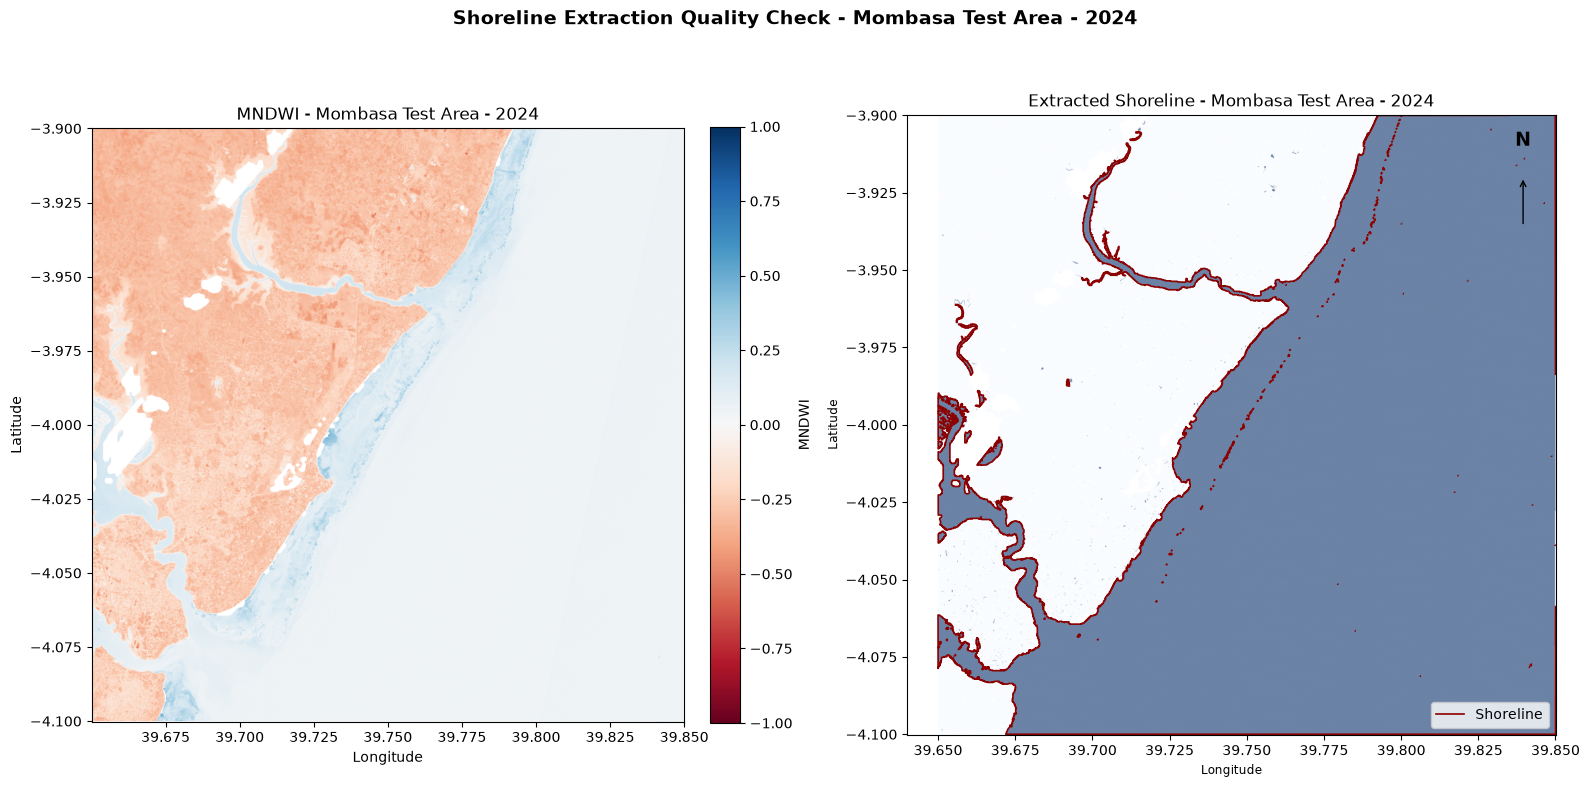

Saved QC figure to: [redacted env]\Documents\Data Science Projects\Shoremonitor\outputs\figures\mombasa_test_shoreline_qc_2024.p
ng


In [12]:
from matplotlib.lines import Line2D
from pyproj import Transformer

FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def lonlat_extent(da):
    transformer = Transformer.from_crs(da.rio.crs, "EPSG:4326", always_xy=True)
    minx, miny, maxx, maxy = da.rio.bounds()
    left, bottom = transformer.transform(minx, miny)
    right, top = transformer.transform(maxx, maxy)
    return [left, right, bottom, top]


shoreline_4326 = shoreline_clipped.to_crs(epsg=4326)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Panel 1: MNDWI
im0 = axes[0].imshow(
    mndwi_da.values, cmap="RdBu", vmin=-1.0, vmax=1.0, extent=lonlat_extent(mndwi_da)
)
axes[0].set_title("MNDWI - Mombasa Test Area - 2024")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label="MNDWI")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

# Panel 2: Water mask + shoreline
axes[1].imshow(
    water_mask_da.values,
    cmap="Blues",
    vmin=0,
    vmax=1,
    extent=lonlat_extent(water_mask_da),
    alpha=0.6,
)
shoreline_4326.plot(ax=axes[1], color="darkred", linewidth=1.2, label="Shoreline")
axes[1].set_title("Extracted Shoreline - Mombasa Test Area - 2024")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

legend_elements = [
    Line2D([0], [0], color="darkred", lw=1.2, label="Shoreline"),
]
axes[1].legend(handles=legend_elements, loc="lower right")

# North arrow
axes[1].annotate(
    "N",
    xy=(0.95, 0.95),
    xycoords="axes fraction",
    fontsize=14,
    fontweight="bold",
    ha="center",
)
axes[1].annotate(
    "",
    xy=(0.95, 0.90),
    xycoords="axes fraction",
    xytext=(0.95, 0.82),
    arrowprops=dict(arrowstyle="->", color="black"),
)

fig.suptitle(
    "Shoreline Extraction Quality Check - Mombasa Test Area - 2024",
    fontsize=14,
    fontweight="bold",
)
fig.tight_layout(rect=[0, 0, 1, 0.96])

qc_figure_path = FIGURES_DIR / "mombasa_test_shoreline_qc_2024.png"
fig.savefig(qc_figure_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved QC figure to:", qc_figure_path)

- **What to inspect:** whether the shoreline follows the true coastline and whether clouds or shadows create false shorelines.
- **Small water bodies:** check whether they create unnecessary shoreline fragments.
- **Threshold:** if the shoreline misses turbid water or includes wet sand, consider adjusting the MNDWI threshold.


## Extraction summary

This is a test shoreline, not a final national shoreline. The next step is QGIS visual validation. The MNDWI threshold and cleanup rules may need adjustment after inspection.


In [15]:
# Load selected scene metadata saved by Notebook 02
selected_scene_meta = pd.read_csv(TEST_DIR / "selected_scene_metadata.csv")
selected_scene_id = selected_scene_meta.loc[0, "scene_id"]
selected_scene_datetime = selected_scene_meta.loc[0, "datetime"]
selected_scene_cloud_cover = selected_scene_meta.loc[0, "cloud_cover"]

shoreline_summary = pd.DataFrame(
    [
        {
            "study_area": "mombasa_test",
            "year": 2024,
            "scene_id": selected_scene_id,
            "acquisition_date": str(selected_scene_datetime),
            "cloud_cover": selected_scene_cloud_cover,
            "mndwi_threshold": 0.0,
            "min_water_polygon_area_m2": 10000,
            "number_water_polygons_raw": len(water_polygons),
            "number_water_polygons_filtered": len(water_polygons_filtered),
            "number_shoreline_features": len(shoreline_clipped),
            "shoreline_length_km": total_length_km,
            "water_area_km2": total_water_area_km2,
            "land_area_km2": land_pixels * pixel_area / 1e6,
            "invalid_pixels": nodata_pixels,
            "water_cover_percent": water_pct,
            "land_cover_percent": land_pct,
        }
    ]
)

summary_path = (
    PROCESSED_DIR / "mombasa_test" / "2024" / "shoreline_extraction_summary_2024.csv"
)
shoreline_summary.to_csv(summary_path, index=False)
print("Saved summary to:", summary_path)
print(shoreline_summary.to_string(index=False))

Saved summary to: [redacted env]\Documents\Data Science Projects\Shoremonitor\data\processed\mombasa_test\2024\shoreline_extract
ion_summary_2024.csv
  study_area  year                                               scene_id                 acquisition_date  cloud_cover  mndwi_t
hreshold  min_water_polygon_area_m2  number_water_polygons_raw  number_water_polygons_filtered  number_shoreline_features  shore
line_length_km  water_area_km2  land_area_km2  invalid_pixels  water_cover_percent  land_cover_percent
mombasa_test  2024 S2A_MSIL2A_20240529T074541_R049_T37MER_20240529T123614 2024-05-29 07:45:41.024000+00:00     0.122262
     0.0                      10000                       1397                              14                         14
        272.14        295.2072       187.0198           95016            61.217476           38.782524
